# 01 ? Download & Dataset Exploration

Notebook ini mengunduh dataset resmi MathWorks dan hanya memasukkan rekaman **CHF** serta **NSR** ke manifest yang dipakai pipeline. Rekaman ARR yang pernah diekstrak tidak dihapus dari disk, tetapi dikecualikan dari pemrosesan dan pelatihan.


In [1]:
from pathlib import Path
import urllib.request
import zipfile
import shutil
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

# Lokasi proyek (notebook dijalankan dari folder notebooks)
ROOT = Path("..") if Path("..").exists() else Path(".")
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WORK_DIR = DATA_DIR / "processed"
DOWNLOAD_DIR = DATA_DIR / "download"
for folder in [RAW_DIR, WORK_DIR, DOWNLOAD_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
FS_TARGET = 128
RECORD_LENGTH = 65536
SOURCE_CLASSES = ["ARR", "CHF", "NSR"]
CLASS_NAMES = ["CHF", "NSR"]


In [2]:
# Unduh paket dataset resmi MathWorks.
# Jika file sudah ada, unduhan dilewati.
archive_url = "https://github.com/mathworks/physionet_ECG_data/archive/refs/heads/main.zip"
archive_path = DOWNLOAD_DIR / "physionet_ECG_data-main.zip"
extracted_repo = DOWNLOAD_DIR / "physionet_ECG_data-main"

if not archive_path.exists():
    print("Mengunduh dataset ECG dari MathWorks...")
    urllib.request.urlretrieve(archive_url, archive_path)
    print("Unduhan selesai:", archive_path)

if not extracted_repo.exists():
    print("Mengekstrak paket utama...")
    with zipfile.ZipFile(archive_path, "r") as zf:
        zf.extractall(DOWNLOAD_DIR)

inner_zip = extracted_repo / "ECGData.zip"
if not inner_zip.exists():
    raise FileNotFoundError(
        "ECGData.zip tidak ditemukan. Periksa isi paket unduhan MathWorks."
    )

mat_dir = DOWNLOAD_DIR / "ECGData_extracted"
mat_dir.mkdir(parents=True, exist_ok=True)
mat_path = mat_dir / "ECGData.mat"

if not mat_path.exists():
    print("Mengekstrak file ECGData.mat...")
    with zipfile.ZipFile(inner_zip, "r") as zf:
        zf.extractall(mat_dir)

if not mat_path.exists():
    raise FileNotFoundError("ECGData.mat tidak ditemukan setelah ekstraksi.")

print("Dataset siap dibaca:", mat_path.resolve())


Dataset siap dibaca: C:\Users\LENOVO\Downloads\ECG_2D_CNN_Project_Dataset_AutoDownload\ECG_2D_CNN_Project\data\download\ECGData_extracted\ECGData.mat


In [3]:
# Baca struktur MATLAB dan batasi manifest proyek ke CHF dan NSR.
mat = sio.loadmat(mat_path, squeeze_me=True, struct_as_record=False)
if "ECGData" not in mat:
    raise KeyError("Variabel 'ECGData' tidak ditemukan di ECGData.mat")

ecg = mat["ECGData"]
if not hasattr(ecg, "Data") or not hasattr(ecg, "Labels"):
    raise ValueError("Struktur ECGData tidak memiliki field Data dan Labels.")

X_all = np.asarray(ecg.Data)
labels_all = np.asarray(ecg.Labels).reshape(-1)
if X_all.ndim != 2:
    raise ValueError(f"Dimensi Data tidak sesuai: {X_all.shape}")
if X_all.shape[0] != len(labels_all) and X_all.shape[1] == len(labels_all):
    X_all = X_all.T

def clean_label(value):
    if isinstance(value, bytes):
        value = value.decode("utf-8")
    return str(value).strip().upper()

labels_all = [clean_label(value) for value in labels_all]
if X_all.shape != (162, RECORD_LENGTH):
    raise ValueError(f"Ukuran dataset sumber tidak sesuai: {X_all.shape}")
if not set(labels_all).issubset(set(SOURCE_CLASSES)):
    raise ValueError(f"Label tidak dikenal: {set(labels_all) - set(SOURCE_CLASSES)}")

source_indices = np.flatnonzero(np.isin(labels_all, CLASS_NAMES))
X_data = X_all[source_indices]
labels = [labels_all[index] for index in source_indices]
counts = pd.Series(labels).value_counts().reindex(CLASS_NAMES, fill_value=0)
print("Ukuran dataset sumber:", X_all.shape)
print("Ukuran dataset yang dipakai:", X_data.shape)
display(counts.rename("jumlah rekaman"))
if X_data.shape != (66, RECORD_LENGTH) or counts.to_dict() != {"CHF": 30, "NSR": 36}:
    raise ValueError(f"Distribusi CHF/NSR tidak sesuai ekspektasi: {counts.to_dict()}")


Ukuran dataset sumber: (162, 65536)
Ukuran dataset yang dipakai: (66, 65536)


CHF    30
NSR    36
Name: jumlah rekaman, dtype: int64

In [4]:
# Simpan hanya rekaman CHF dan NSR. ID tetap mengikuti posisi rekaman pada sumber.
manifest_rows = []
for source_index, signal, label in zip(source_indices, X_data, labels):
    class_dir = RAW_DIR / label
    class_dir.mkdir(parents=True, exist_ok=True)

    record_id = f"{label}_{source_index + 1:03d}"
    out_path = class_dir / f"{record_id}.npy"
    signal = np.asarray(signal, dtype=np.float32).reshape(-1)

    if len(signal) != RECORD_LENGTH:
        raise ValueError(f"{record_id}: panjang sinyal {len(signal)}, seharusnya {RECORD_LENGTH}")
    if not np.all(np.isfinite(signal)):
        raise ValueError(f"{record_id}: terdapat NaN atau Inf.")

    np.save(out_path, signal)
    manifest_rows.append({
        "record_id": record_id,
        "label": label,
        "path": str(out_path.resolve()),
        "fs": FS_TARGET,
        "format": "npy"
    })

manifest = pd.DataFrame(manifest_rows)
manifest_path = WORK_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Jumlah rekaman tersimpan:", len(manifest))
display(manifest.groupby("label").size().reindex(CLASS_NAMES, fill_value=0).rename("jumlah rekaman"))
print("Manifest:", manifest_path.resolve())


Jumlah rekaman tersimpan: 66


label
CHF    30
NSR    36
Name: jumlah rekaman, dtype: int64

Manifest: C:\Users\LENOVO\Downloads\ECG_2D_CNN_Project_Dataset_AutoDownload\ECG_2D_CNN_Project\data\processed\manifest.csv


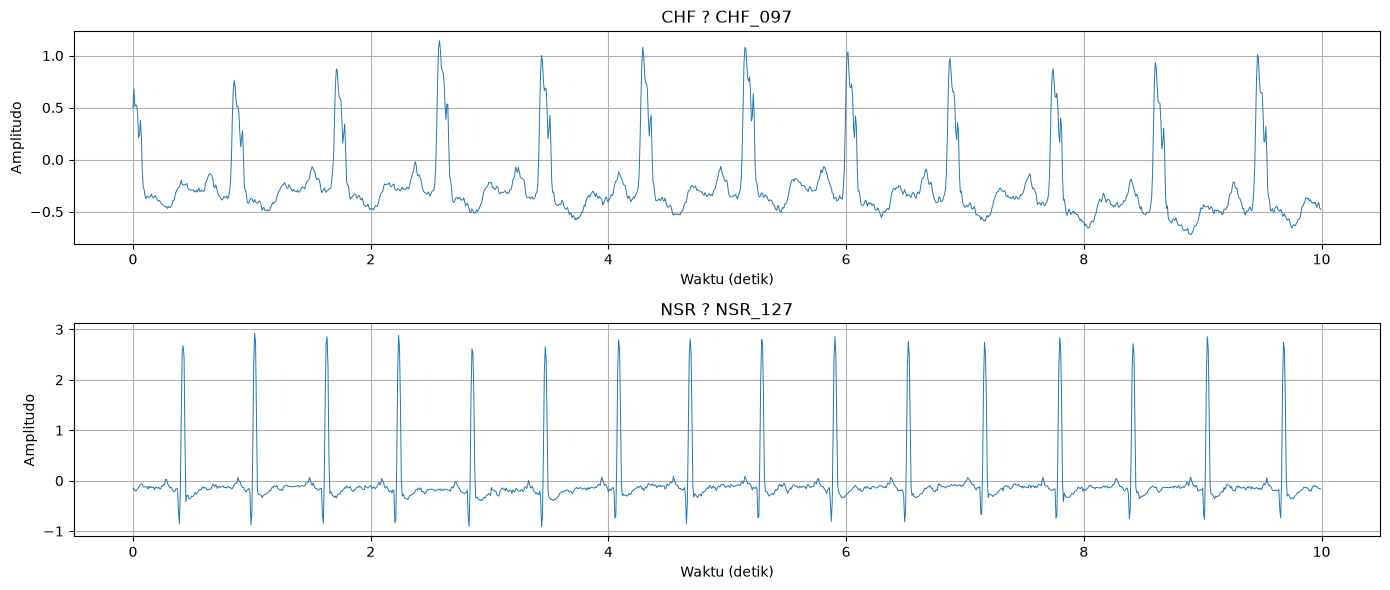

In [5]:
# Visualisasi satu rekaman dari tiap kelas yang digunakan.
fig, axes = plt.subplots(len(CLASS_NAMES), 1, figsize=(14, 6))
for ax, label in zip(np.atleast_1d(axes), CLASS_NAMES):
    row = manifest[manifest["label"] == label].iloc[0]
    signal = np.load(row["path"])
    seconds = min(10, len(signal) / FS_TARGET)
    n = int(seconds * FS_TARGET)
    t = np.arange(n) / FS_TARGET
    ax.plot(t, signal[:n], linewidth=0.7)
    ax.set_title(f"{label} ? {row['record_id']}")
    ax.set_xlabel("Waktu (detik)")
    ax.set_ylabel("Amplitudo")
    ax.grid(True)
plt.tight_layout()
plt.show()


**Selesai:** `data/processed/manifest.csv` berisi hanya 30 rekaman CHF dan 36 rekaman NSR. File sumber ARR yang sudah ada tetap tersimpan, tetapi tidak disertakan dalam manifest proyek. Dataset ini berasal dari repositori MathWorks/PhysioNet dan tunduk pada lisensi yang disertakan dalam arsip.
